In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')

In [4]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
df.shape

(2443651, 9)

In [8]:
# Displaying the data types of each column in the dataframe
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [9]:
# Retrieving the unique data types present in the dataframe columns
list(set(df.dtypes.tolist()))

[dtype('float64'), dtype('bool'), dtype('O'), dtype('int64')]

In [10]:
#Part 1: Understanding Product Categories
pd.crosstab(index = df ["category"], columns = "count")



col_0,count
category,
3D Printers,248
3D Printing & Scanning,4067
Abrasive & Finishing Products,250
Action Cameras,1697
Adapters,254
...,...
Wind Instruments,250
Window Treatments,239
Women,17772


In [11]:
#Top 5 most liked product categories
top_categories = df['category'].value_counts().head(5)

top_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

/var/folders/bp/q0jpdzq126j54kx_lzjc4dcm0000gn/T/ipykernel_73885/1233466950.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.index, y=top_categories.values, palette='viridis')


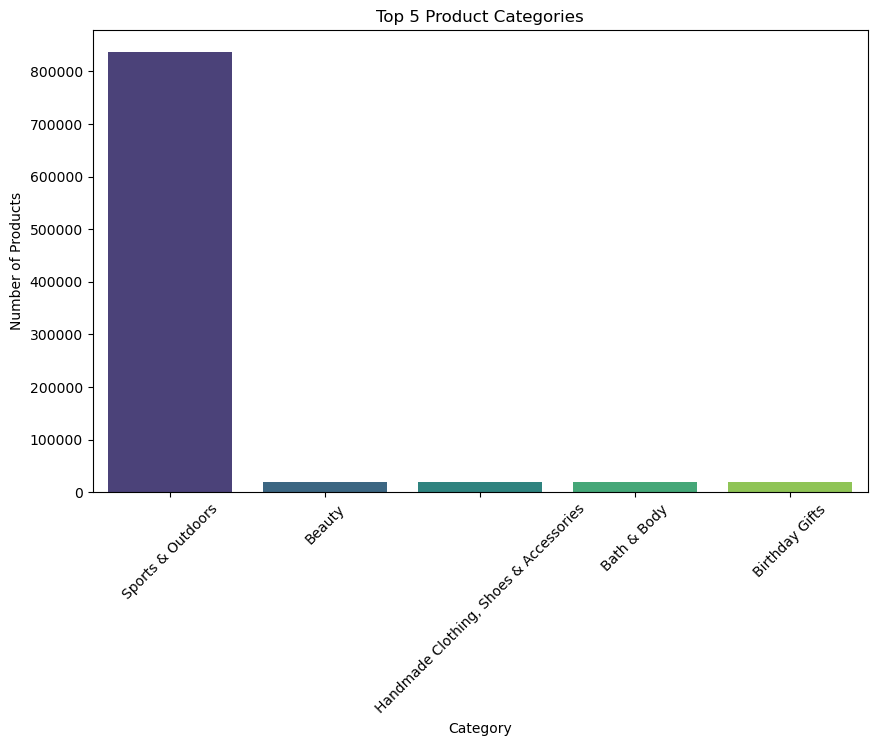

In [12]:
#Display the distribution of products accross different categories using a bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=top_categories.index, y=top_categories.values, palette='viridis')
plt.title('Top 5 Product Categories')
plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=45)
plt.show()

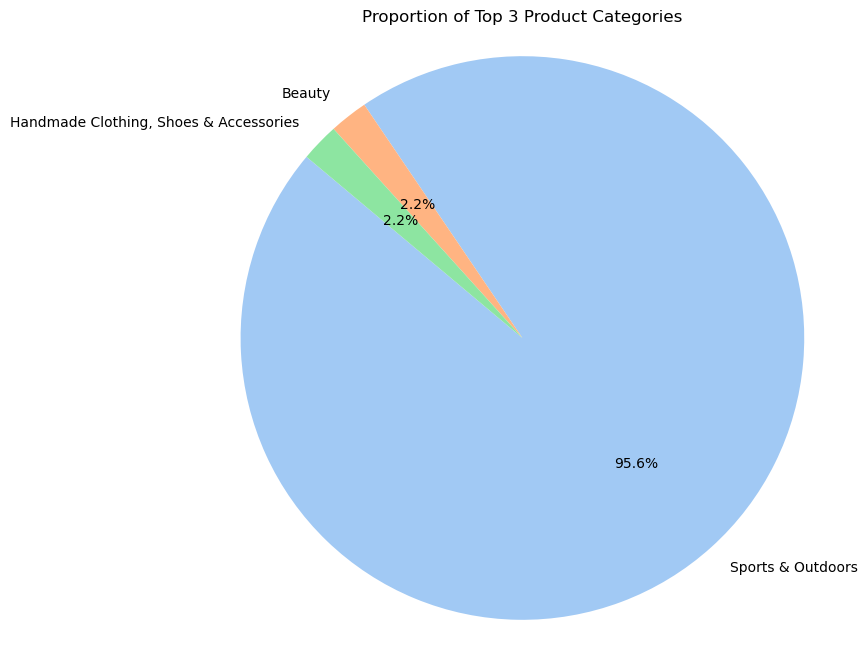

In [13]:
#For a subset of top categories, visualize their proportions using a pie chart
top_categories_subset = top_categories.head(3)
plt.figure(figsize=(8, 8))
plt.pie(top_categories_subset, labels=top_categories_subset.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel', n_colors=len(top_categories_subset)))
plt.title('Proportion of Top 3 Product Categories')
plt.axis('equal')  # Equal aspect ratio ensures that pie chart is a circle.
plt.show()

In [14]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [ ]:
#Part 2: Measures of Centrality
mean_price = df["price"].mean()  # Calculate the mean of the 'price' column
median_price = df["price"].median()  # Calculate the median of the 'price' column
mode_price = df["price"].mode() [0]  # Calculate the mode of the 'price' column

mean_price, median_price, mode_price


(np.float64(89.24380943923663), 19.09, np.float64(9.99))

In summary:

- Most products are inexpensive (as shown by the mode and median).

- A small group of expensive products raises the mean to 89 €.

- To describe a “typical” product price, the median or mode is more reliable than the mean.

- The price distribution likely has a long right tail

In [ ]:
skewness_price = df['price'].skew()
skewness_price

np.float64(27.492977566280338)

The skewness of the price variable is 27.49, which indicates an extremely right-skewed distribution. Most products are concentrated at low prices, but a small number of extremely expensive items create a very long right tail, heavily influencing the mean.

In [18]:
#Measures of Dispersion
var_price = df["price"].var(ddof=0)  # Calculate the variance of the 'price' column
std_price = df["price"].std(ddof=0)  # Calculate the standard deviation of the 'price' column

min_price = df["price"].min()  # Calculate the minimum value of the 'price' column
max_price = df["price"].max()  # Calculate the maximum value of the 'price' column
range_price = max_price - min_price  # Calculate the range of the 'price' column

q1, q2, q3 = df["price"].quantile([0.25, 0.5, 0.75])  # Calculate the first, second (median), and third quartiles of the 'price' column

var_price, std_price, min_price, max_price, range_price, q1, q2, q3

(119445.43644263715,
 345.6087910378397,
 0.0,
 100000.0,
 100000.0,
 9.99,
 19.09,
 45.99)

In [19]:
# Discretizing 'price' into quartiles
df['price_quantile'] = pd.qcut(df['price'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])

df["price_quantile"].value_counts()

price_quantile
Q1    629239
Q3    612341
Q4    609043
Q2    593028
Name: count, dtype: int64

In [20]:
pd.qcut(df['price'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'], retbins=True)

(0          Q3
 1          Q3
 2          Q3
 3          Q3
 4          Q2
            ..
 2443646    Q3
 2443647    Q4
 2443648    Q4
 2443649    Q4
 2443650    Q4
 Name: price, Length: 2443651, dtype: category
 Categories (4, object): ['Q1' < 'Q2' < 'Q3' < 'Q4'],
 array([0.000e+00, 9.990e+00, 1.909e+01, 4.599e+01, 1.000e+05]))

The analysis shows that product prices are highly dispersed. While the overall price range extends from 0 € to 100,000 €, with a very large standard deviation of 345 €, the quartile values reveal a different picture. Half of the products are priced between 9.99 € and 45.99 €, with a median of 19.09 €, indicating that the majority of items fall within an affordable range. However, the presence of a small number of extremely expensive products creates a long right tail, which significantly inflates both the mean and the standard deviation. In summary, most products are relatively low-priced, but a few extreme outliers generate a very wide spread in the data.



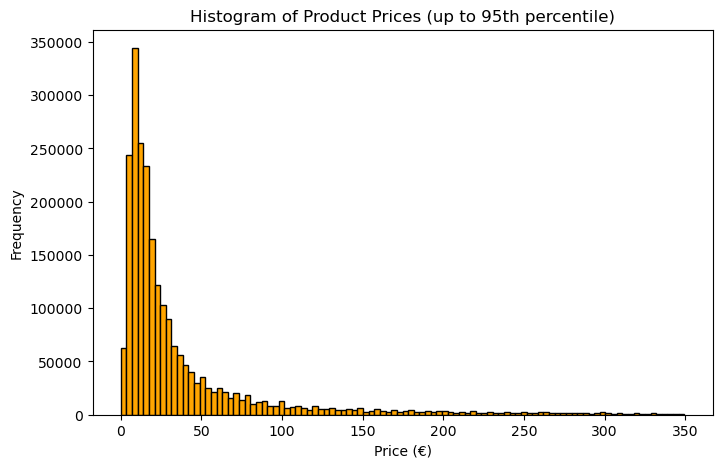

In [25]:
#Visualize the distribution of product prices by histogram plot

upper_limit = df["price"].quantile(0.95)

plt.figure(figsize=(8,5))
plt.hist(df[df["price"] <= upper_limit]["price"], bins=100, color="orange", edgecolor="black")
plt.title("Histogram of Product Prices (up to 95th percentile)")
plt.xlabel("Price (€)")
plt.ylabel("Frequency")
plt.show()

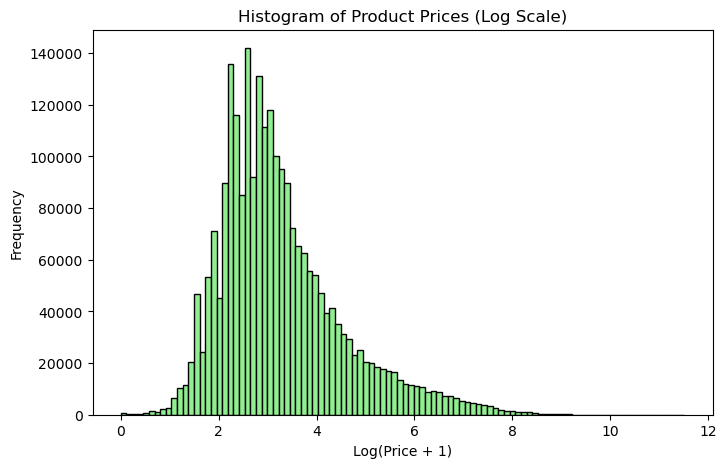

In [ ]:
#Antoher Approach with all the data:
plt.figure(figsize=(8,5))
plt.hist(np.log1p(df["price"]), bins=100, color="lightgreen", edgecolor="black")
plt.title("Histogram of Product Prices (Log Scale)")
plt.xlabel("Log(Price + 1)")
plt.ylabel("Frequency")
plt.show()

The histogram shows that most products fall within a low-price range. Specifically, the majority of items are priced between approximately 10 € and 50 €, with the median at 19.09 €. However, the histogram is difficult to interpret when plotted on the full scale, because a few extremely expensive products (up to 100,000 €) create a very long right tail. This results in one large bar near zero and very small or invisible bars elsewhere.
Solution: To make the visualization clearer, we can either (1) limit the x-axis to a reasonable range (e.g., up to the 95th percentile), or (2) apply a logarithmic transformation (log(price+1)), which compresses the scale and allows the lower-priced products to be more visible.

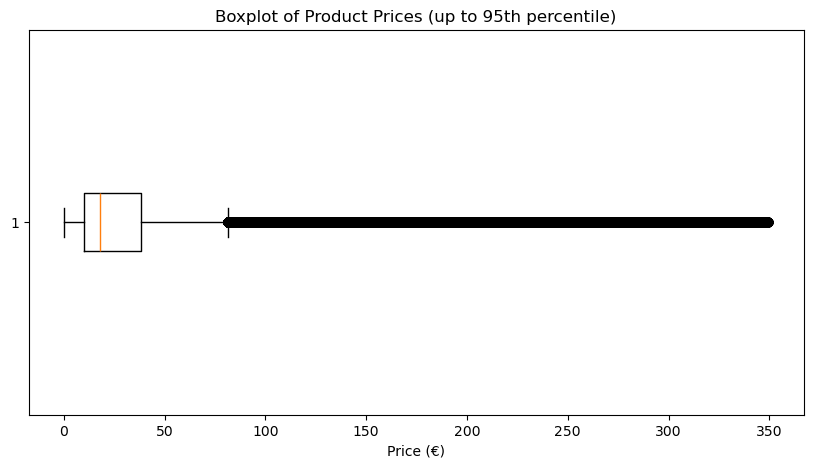

In [28]:
plt.figure(figsize=(10,5))
plt.boxplot(df[df["price"] <= df["price"].quantile(0.95)]["price"], vert=False)
plt.title("Boxplot of Product Prices (up to 95th percentile)")
plt.xlabel("Price (€)")
plt.show()

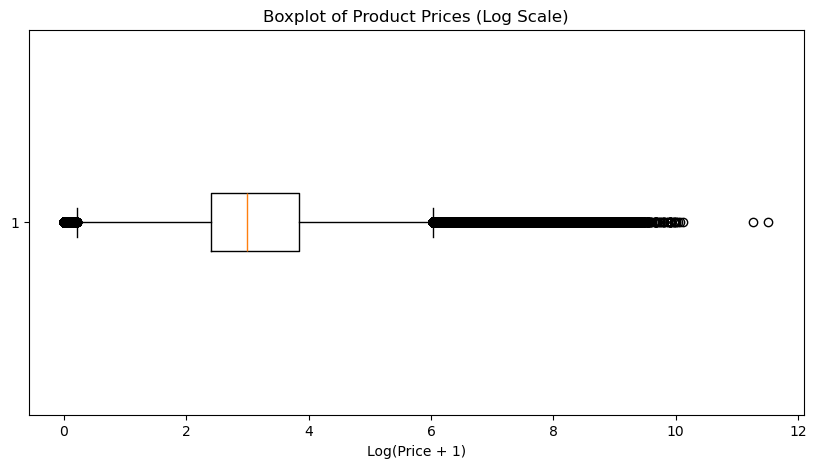

In [29]:
plt.figure(figsize=(10,5))
plt.boxplot(np.log1p(df["price"]), vert=False)
plt.title("Boxplot of Product Prices (Log Scale)")
plt.xlabel("Log(Price + 1)")
plt.show()

The box plot clearly shows that while most products fall within a relatively narrow range, there are extreme outliers priced far above the majority. With Q3 at 45.99 €, but a maximum price of 100,000 €, it is evident that a small group of very expensive products drives the extreme skewness in the data. These items are significantly higher than the rest and distort the mean and standard deviation, confirming the presence of strong outliers in the dataset.

In [30]:
#Part 3: Unpacking Product Ratings
#Measures of centrality

mean_rating = df["stars"].mean()  # Calculate the mean of the 'stars' column
median_rating = df["stars"].median()  # Calculate the median of the 'stars' column
mode_rating = df["stars"].mode() [0]  # Calculate the mode of the 'stars' column

mean_rating, median_rating, mode_rating

(np.float64(2.152836472966065), 0.0, np.float64(0.0))

Customers generally rate products very positively, with most ratings close to 5 stars. However, the common trend is that many products have few or no reviews, so only a small portion of products accumulate most of the feedback.

In [31]:
#Measures of dispersion
var_rate = df["stars"].var(ddof=0)  # Calculate the variance of the 'stars' column
std_rate = df["stars"].std(ddof=0)  # Calculate the standard deviation of the 'stars' column

min_rate = df["stars"].min()  # Calculate the minimum value of the 'stars' column
max_rate = df["stars"].max()  # Calculate the maximum value of the 'stars' column
range_rate = max_rate - min_rate  # Calculate the range of the 'stars' column

q1, q2, q3 = df["stars"].quantile([0.25, 0.5, 0.75])  # Calculate the first, second (median), and third quartiles of the 'stars' column

var_rate, std_rate, min_rate, max_rate, range_rate, q1, q2, q3

(4.8174320583535915, 2.194864929409915, 0.0, 5.0, 5.0, 0.0, 0.0, 4.4)

Ratings are not very consistent. Most products have few or no reviews, as reflected by the median and first quartile being 0. Among the products that do have ratings, there is a wide variation, ranging from very low to very high scores. Overall, customer feedback is highly dispersed and skewed toward products with no ratings.

In [32]:
#Shape of the Distribution

skewness_rate = df['stars'].skew()
kurtosis_rate = df['stars'].kurtosis()

skewness_rate, kurtosis_rate

(np.float64(0.08120735761080985), np.float64(-1.9260061280432985))

The ratings are nearly symmetric, as indicated by a skewness close to zero, meaning they are not strongly biased toward higher or lower values. However, the negative kurtosis shows that the distribution is flat (platykurtic), with lighter tails and less concentration around the center, so it does not follow a perfect normal distribution.

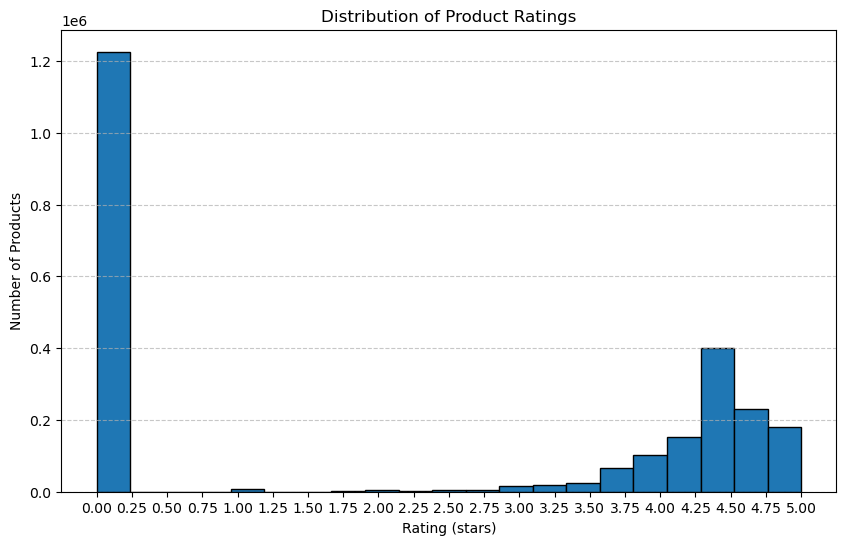

In [33]:
plt.figure(figsize=(10,6))
plt.hist(df['stars'], bins=21, edgecolor='black')  # 0 to 5 in 0.25 steps
plt.title('Distribution of Product Ratings')
plt.xlabel('Rating (stars)')
plt.ylabel('Number of Products')
plt.xticks([i*0.25 for i in range(21)])  # marks every 0.25 stars
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

When plotting a histogram of product ratings, it is clear that the most common rating is 0, meaning many products have no reviews. Among the products that have ratings, higher values (around 4–5 stars) appear more frequently, reflecting that customers tend to rate positively. The histogram is heavily skewed toward products with no ratings, which makes it hard to clearly see the distribution of actual ratings.